# HD-PROCOVA Results

Visualize cross-validation and final model results from the HBM + ML pipeline on simulated data.

Run these first:
```bash
python scripts/generate_data.py
python scripts/train_cv.py      
python scripts/train_final.py      
```

In [75]:
%config InlineBackend.figure_format = 'retina'

import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = (Path.cwd() / '..').resolve()
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'training'
FINAL_DIR   = PROJECT_ROOT / 'outputs' / 'final'

sys.path.insert(0, str(PROJECT_ROOT))
from src.figures import (
    plot_r2_by_model, plot_r2_over_time, plot_feature_importance,
    best_model_by_r2, MODEL_PRETTY,
)

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 0. Load the results

In [76]:
def _load_csvs(base_dir, pattern, extra_cols):
    frames = []
    for fp in sorted(base_dir.glob(pattern)):
        df = pd.read_csv(fp)
        for col, fn in extra_cols.items():
            df[col] = fn(fp)
        frames.append(df)
    return pd.concat(frames, ignore_index=True) if frames else None

cv_df = _load_csvs(
    RESULTS_DIR, '**/results_fold_*.csv',
    {'model': lambda fp: fp.parent.name,
     'fold': lambda fp: int(re.search(r'fold_(\d+)', fp.name).group(1))}
)
print(f'CV: {len(cv_df)} rows | Models: {sorted(cv_df["model"].unique())}' if cv_df is not None
      else 'No CV results found. Run: python scripts/train_cv.py')

final_df = _load_csvs(
    FINAL_DIR, '**/predictions.csv',
    {'model': lambda fp: fp.parent.name}
)
print(f'Final: {len(final_df)} rows | Models: {sorted(final_df["model"].unique())}' if final_df is not None
      else 'No final results found. Run: python scripts/train_final.py')

imp_df = _load_csvs(
    RESULTS_DIR, '**/importance_fold_*.csv',
    {'model': lambda fp: fp.parent.name,
     'fold': lambda fp: int(re.search(r'fold_(\d+)', fp.name).group(1))}
)
print(f'Importance: {len(imp_df)} rows' if imp_df is not None
      else 'No importance files found. Run: python scripts/train_cv.py')

CV: 85428 rows | Models: ['decision_tree', 'elasticnet', 'histgradientboosting', 'lasso', 'lightgbm', 'random_forest', 'ridge', 'svr', 'xgboost']
Final: 10368 rows | Models: ['decision_tree', 'elasticnet', 'histgradientboosting', 'lasso', 'lightgbm', 'random_forest', 'ridge', 'svr', 'xgboost']
Importance: 9180 rows


### 1. Models performace

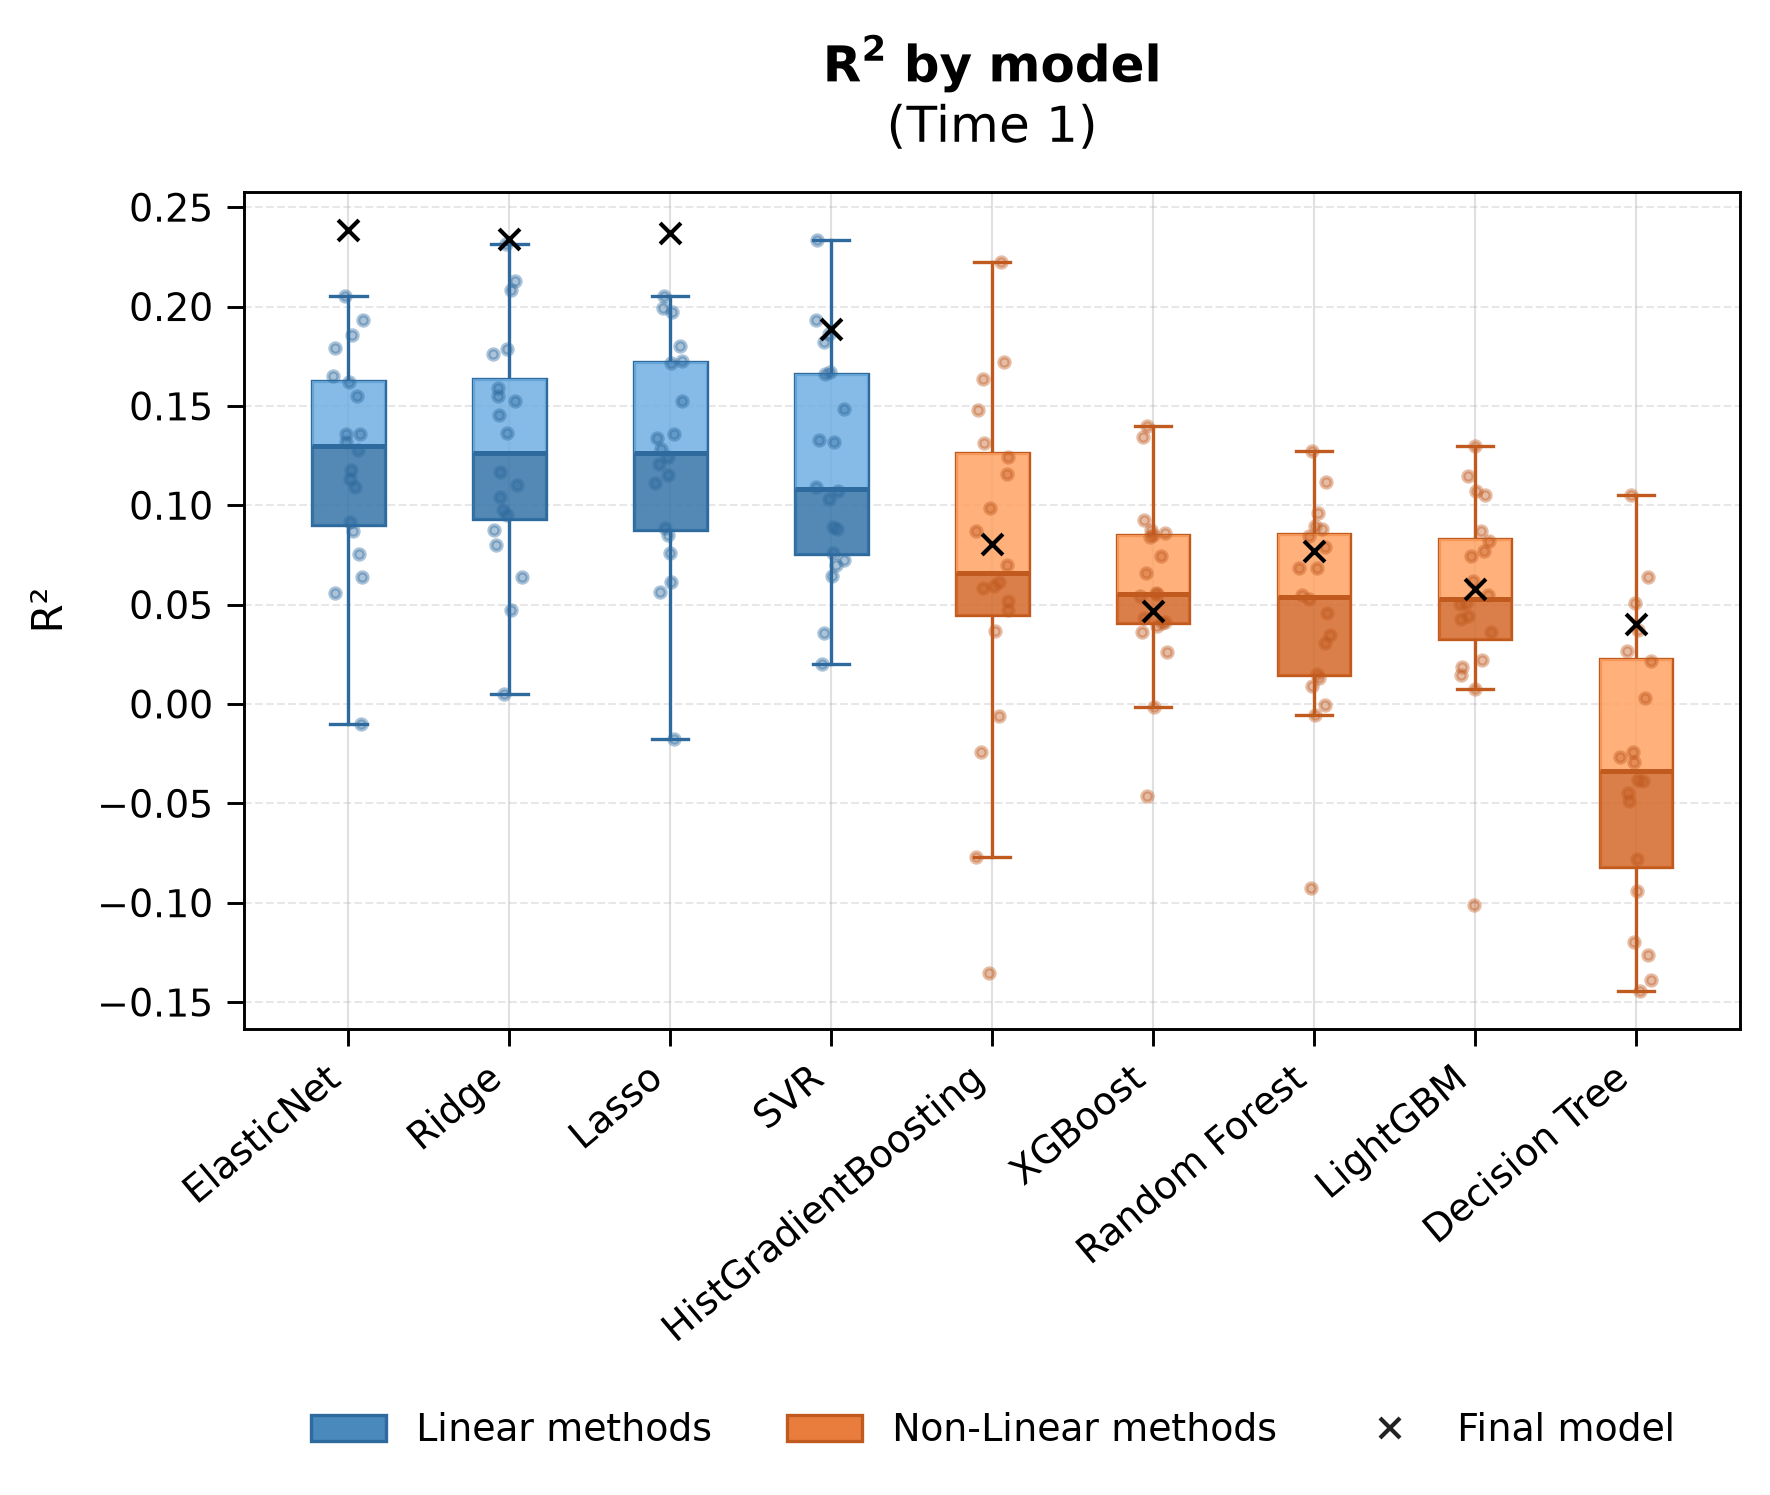

In [83]:
# Select the time visit to plot
SELECTED_TIME = 1
cv_visit_df = cv_df[cv_df['time'] == SELECTED_TIME]

plot_r2_by_model(cv_visit_df, final_df, SELECTED_TIME)

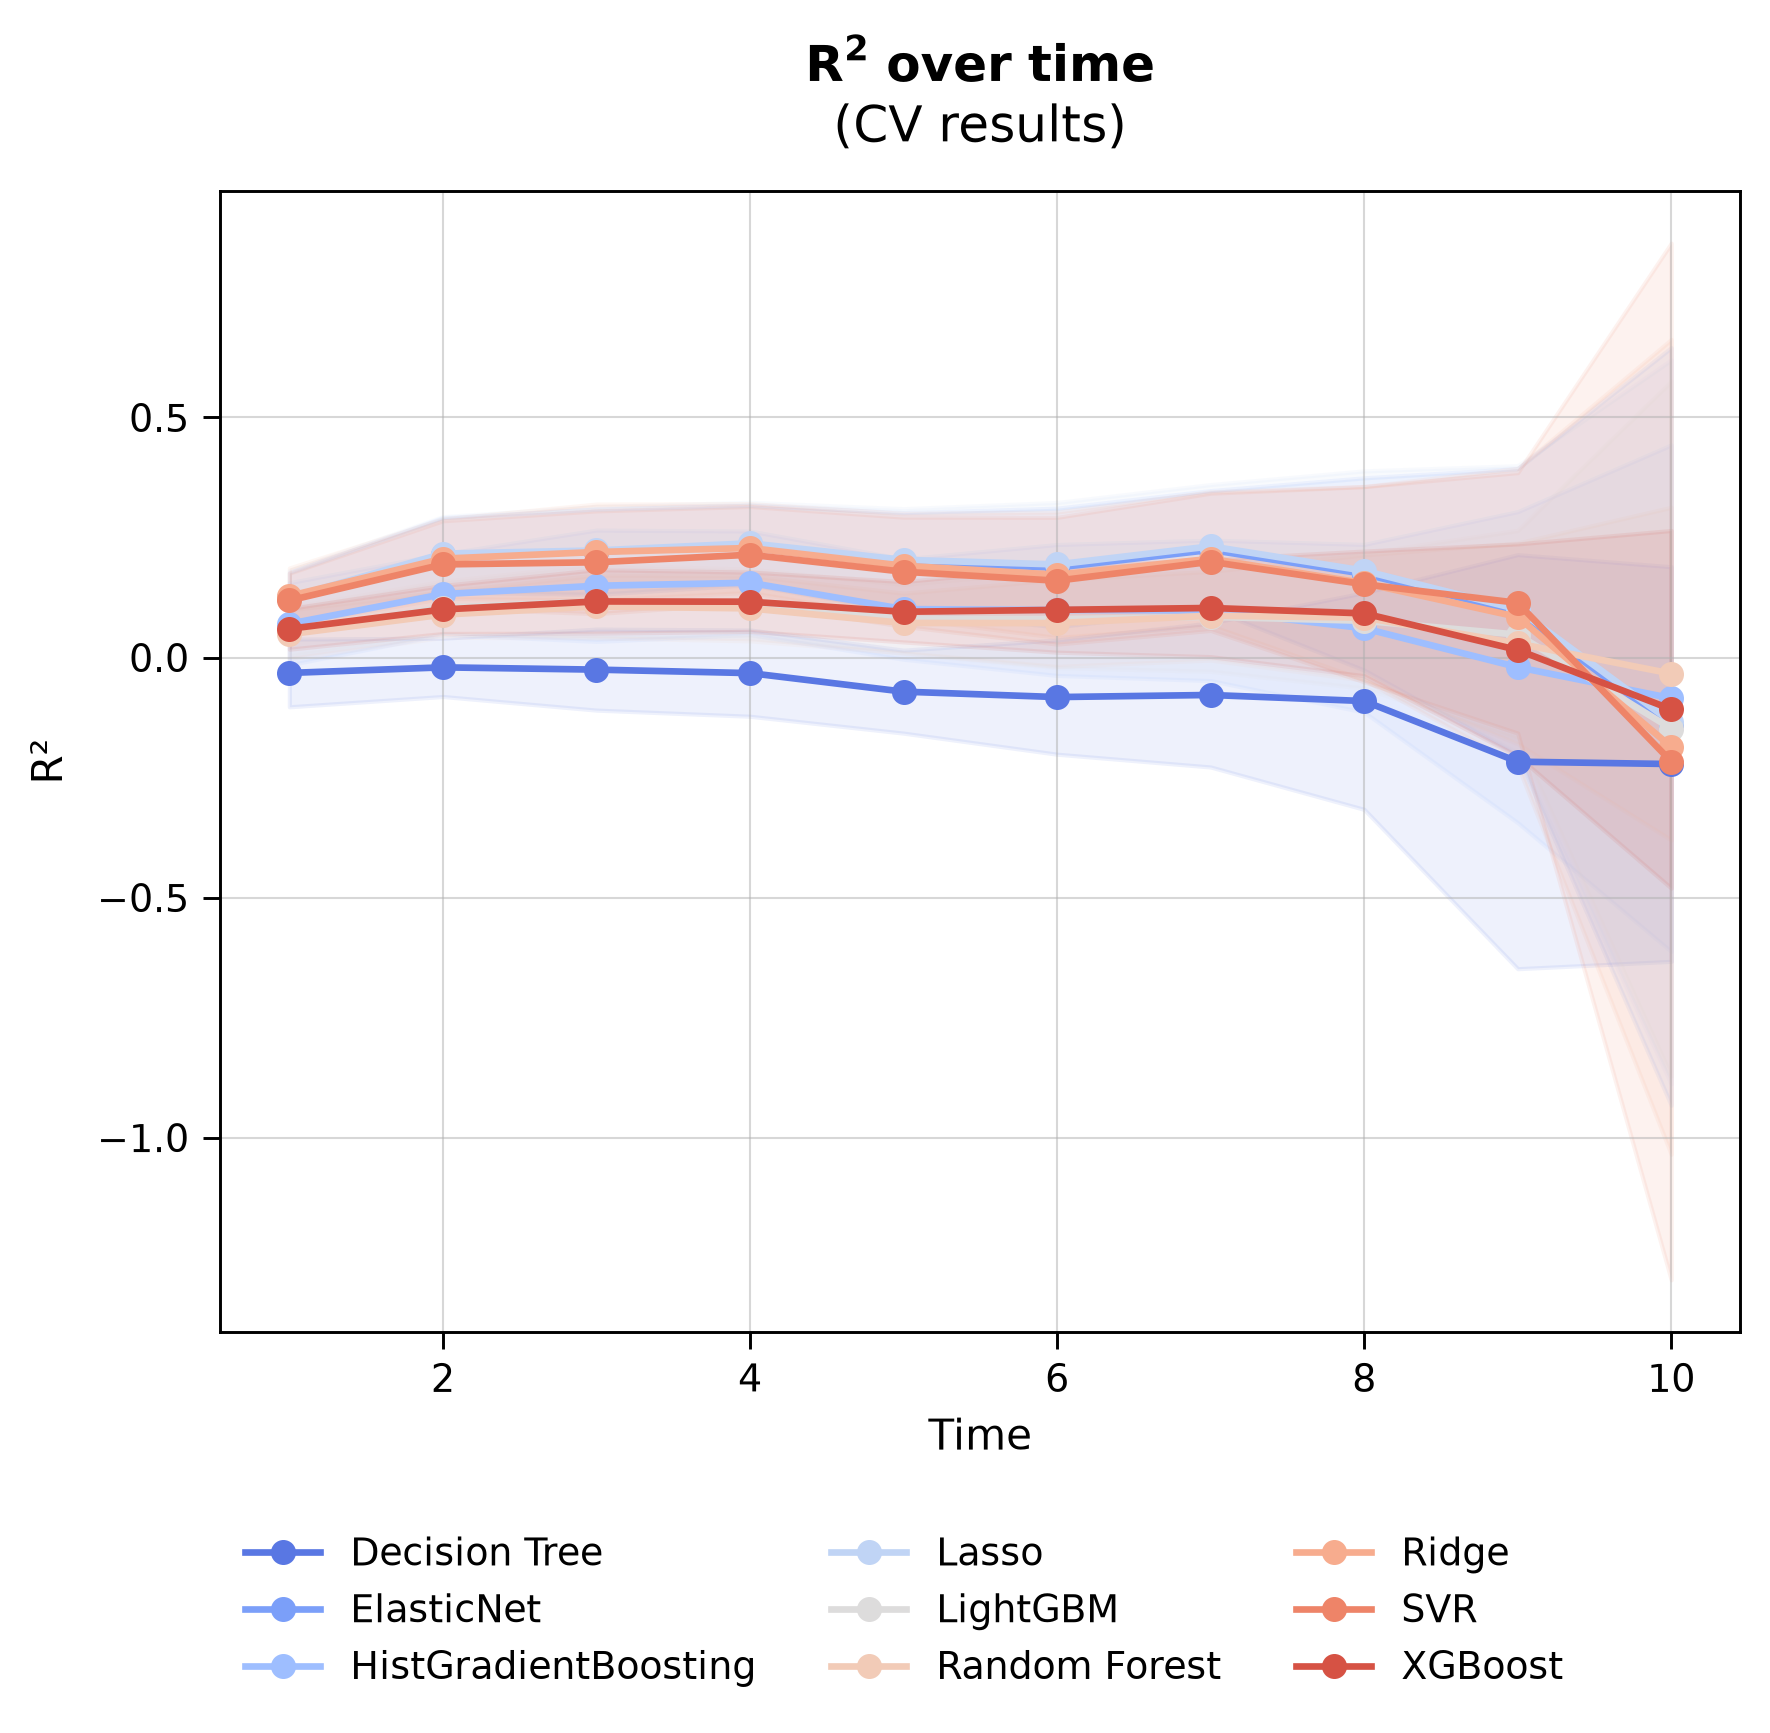

In [85]:
plot_r2_over_time(cv_df)

### 2. Feature importance

Best model by median R²: Lasso


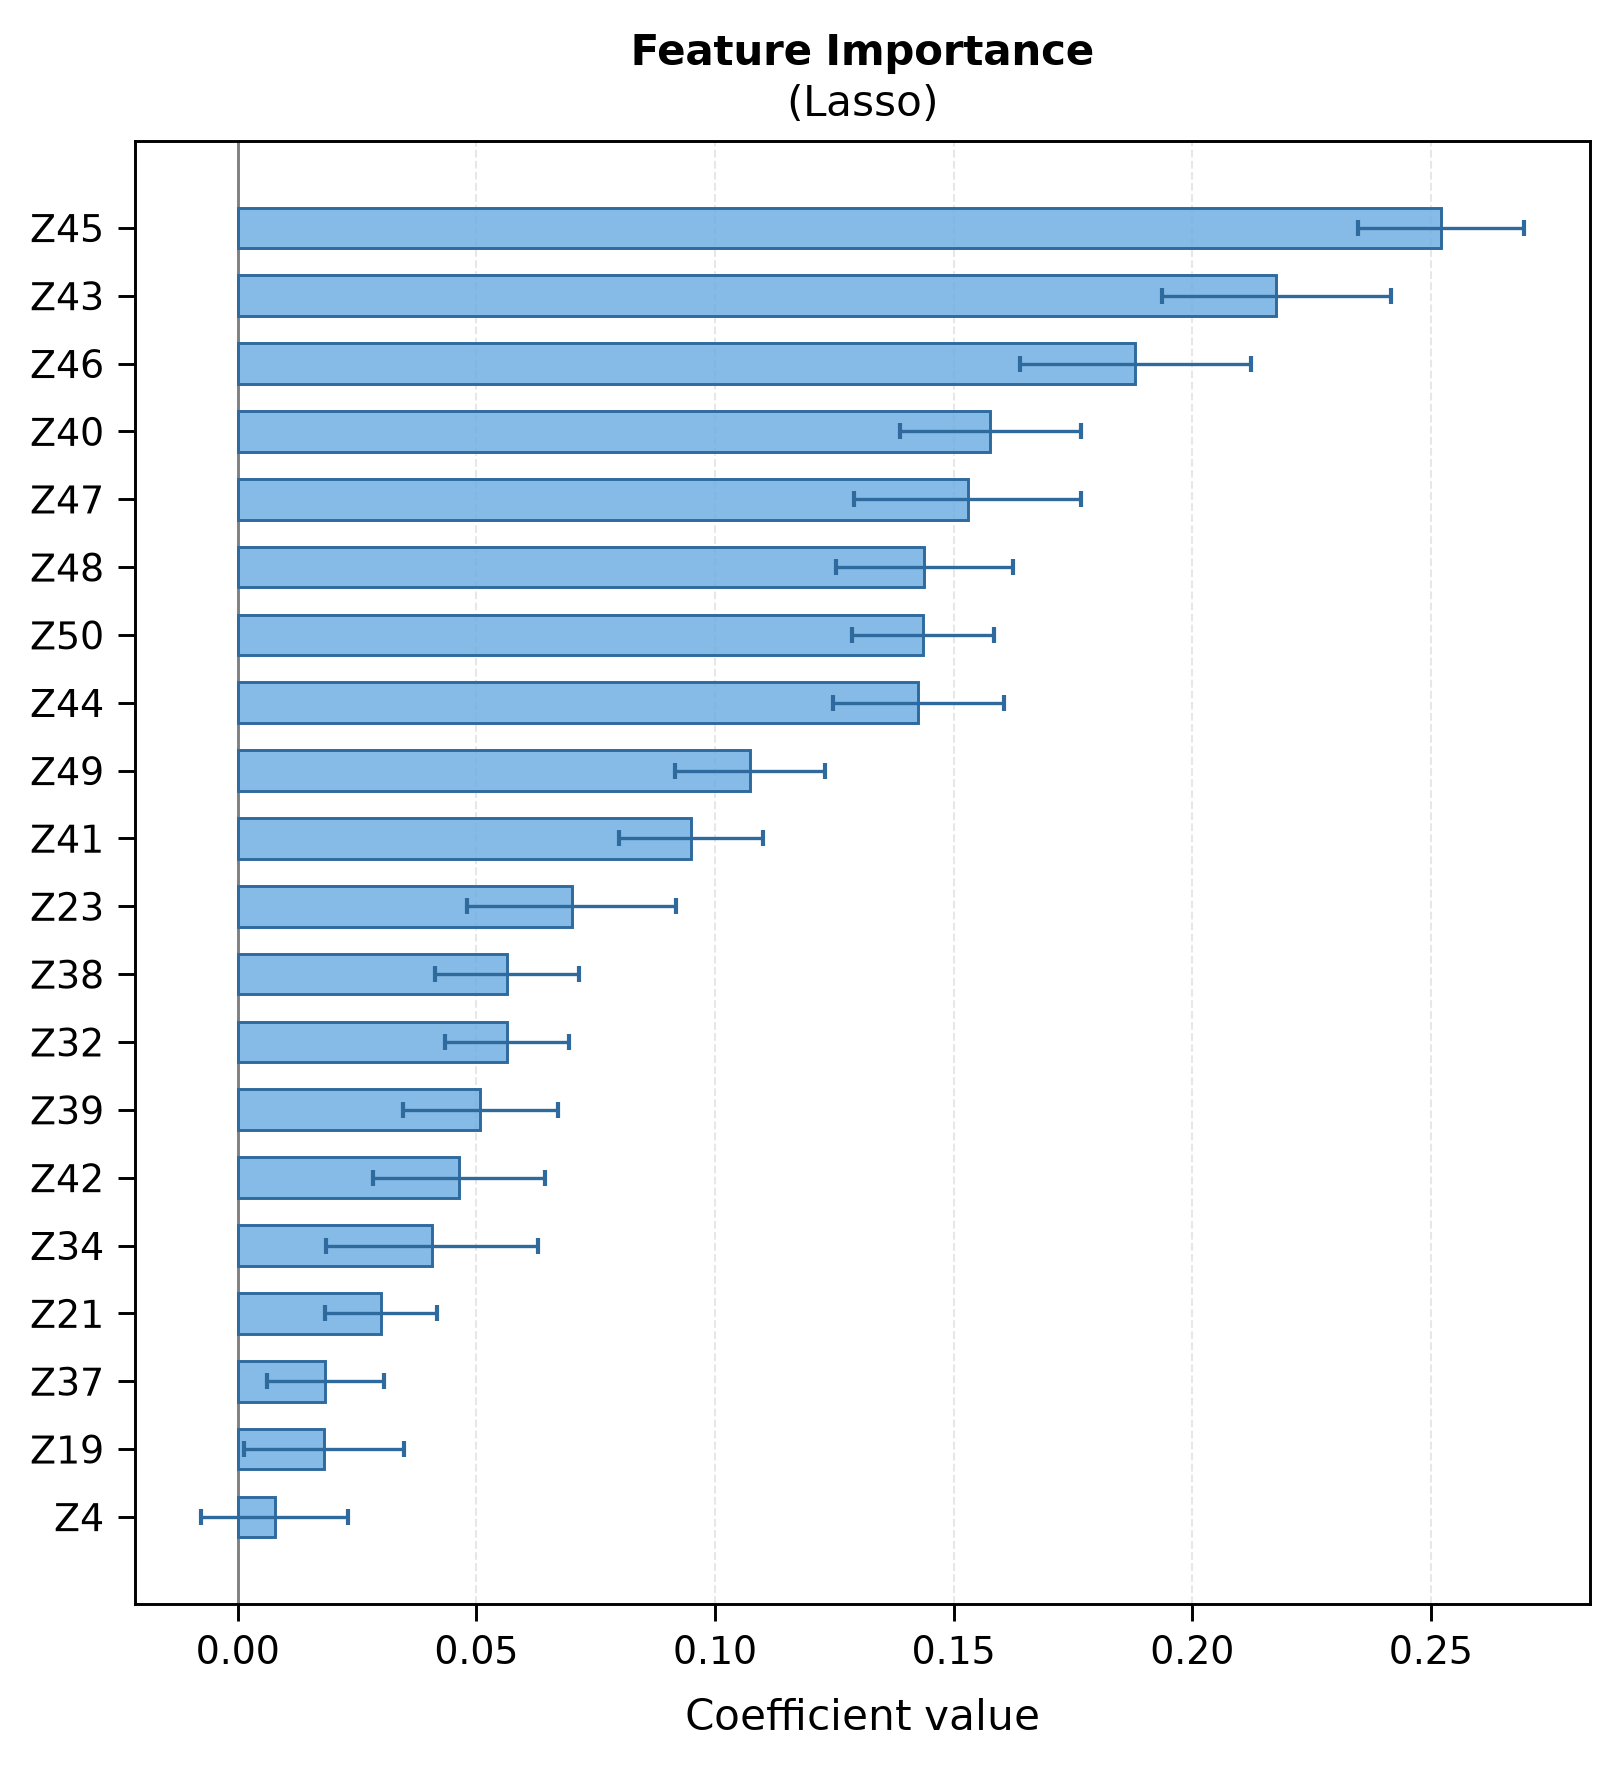

In [79]:
if cv_df is not None and imp_df is not None:
    best_model = best_model_by_r2(cv_df)
    print(f'Best model by median R²: {MODEL_PRETTY.get(best_model, best_model)}')
    plot_feature_importance(imp_df, best_model)